In [1]:
##Initialization
%matplotlib widget
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
import numpy as np
from IPython.display import HTML, display

team_colors = {
    'DEN': 'orange', 'SEA': 'green', 'football': 'brown',
    'TB': 'red', 'DAL': 'navy', 'TEN': 'lightblue',
    'NYG': 'blue', 'MIN': 'purple', 'GB': 'green',
    'LV': 'black', 'LAC': 'yellow', 'KC': 'red',
    'ARI': 'darkred', 'JAX': 'teal', 'WAS': 'burgundy',
    'NYJ': 'green', 'BAL': 'purple', 'MIA': 'aqua',
    'NE': 'navy', 'IND': 'blue', 'HOU': 'darkblue',
    'PHI': 'darkgreen', 'DET': 'blue', 'CIN': 'orange',
    'PIT': 'yellow', 'SF': 'red', 'CHI': 'darkorange',
    'CLE': 'brown', 'CAR': 'lightblue', 'NO': 'black',
    'ATL': 'red', 'BUF': 'blue', 'LA': 'blue'
}
df = pd.read_csv('tracking_week_1.csv')
play_description = pd.read_csv('plays.csv')

In [2]:
import gudhi as gd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

class VRTEAMATNIM:
    def __init__(self, df, play_description, max_edge_length):
        self.df = df
        self.play_desc = play_description
        self.unique_nflids = df[df['nflId'].notna()]['nflId'].unique()
        self.unique_gameids = df['gameId'].unique()
        self.unique_playids = df['playId'].unique()
        self.max_edge_length = max_edge_length
        self.vr_elements = []  # To track VR complex elements
        self.betti_text = None  # To track Betti number display

    def get_teams(self, gameId, playId):
        """Identify the offensive and defensive teams for a specific play."""
        if self.play_desc is None:
            raise ValueError("Play data not loaded. Please check the file path.")

        play_info = self.play_desc[(self.play_desc['gameId'] == gameId) &
                                   (self.play_desc['playId'] == playId)]
        
        if play_info.empty:
            raise ValueError(f"No play data found for gameId={gameId}, playId={playId}")

        offense = play_info.iloc[0]['possessionTeam']
        defense = play_info.iloc[0]['defensiveTeam']
        return offense, defense

    def calculate_persistence_diagram(self, gameId, playId):
        """
        Calculate the persistence diagram for all frames of a play.
        
        Parameters:
        -----------
        gameId : int
            The game ID to analyze
        playId : int
            The play ID to analyze
            
        Returns:
        --------
        dict containing:
            'diagrams': list of persistence diagrams for each frame
            'birth_times': list of birth times for persistence features
            'death_times': list of death times for persistence features
            'max_persistence': maximum persistence value across all frames
        """
        play_data = self.df[(self.df['gameId'] == gameId) & 
                            (self.df['playId'] == playId)].copy()
        
        # Get defensive team
        defensive_team = self.play_desc[(self.play_desc['gameId'] == gameId) & 
                                        (self.play_desc['playId'] == playId)]['defensiveTeam'].values[0]
        
        # Initialize storage for persistence data
        persistence_data = {
            'diagrams': [],
            'birth_times': [],
            'death_times': [],
            'max_persistence': 0
        }
        
        # Process each frame
        num_frames = len(play_data[play_data['nflId'].isna()])  # Use ball data for frame count
        
        for frame_idx in range(num_frames):
            # Get defensive positions for current frame
            defense_positions = []
            for nflId in play_data[play_data['nflId'].notna()]['nflId'].unique():
                player_data = play_data[play_data['nflId'] == nflId]
                if player_data['club'].iloc[0] == defensive_team:
                    x = player_data['x'].values[frame_idx]
                    y = player_data['y'].values[frame_idx]
                    defense_positions.append([x, y])
            
            if defense_positions:
                # Create Vietoris-Rips complex and calculate persistence
                defense_positions = np.array(defense_positions)
                rips_complex = gd.RipsComplex(points=defense_positions, 
                                            max_edge_length=self.max_edge_length)
                simplex_tree = rips_complex.create_simplex_tree(max_dimension=2)
                
                # Calculate persistence diagram
                persistence = simplex_tree.persistence()
                
                # Store diagram and extract birth/death times
                persistence_data['diagrams'].append(persistence)
                
                for point in persistence:
                    if point[0] in [0, 1]:  # Only consider 0D and 1D features
                        birth, death = point[1]
                        if death != float('inf'):  # Exclude infinite death times
                            persistence_data['birth_times'].append(birth)
                            persistence_data['death_times'].append(death)
                            persistence_data['max_persistence'] = max(
                                persistence_data['max_persistence'],
                                death - birth
                            )
        
        return persistence_data
    
    def plot_persistence_diagram(self, persistence_data, frame_idx=None):
        """
        Plot the persistence diagram for a specific frame or all frames combined.
        
        Parameters:
        -----------
        persistence_data : dict
            Output from calculate_persistence_diagram
        frame_idx : int, optional
            If provided, plot diagram for specific frame. 
            If None, plot combined diagram for all frames.
        """
        plt.figure(figsize=(8, 8))
        
        if frame_idx is not None:
            # Plot single frame
            diagram = persistence_data['diagrams'][frame_idx]
            title = f'Persistence Diagram - Frame {frame_idx}'
        else:
            # Combine all diagrams
            diagram = []
            for d in persistence_data['diagrams']:
                diagram.extend(d)
            title = 'Combined Persistence Diagram - All Frames'
        
        # Setup plot
        plt.title(title)
        plt.xlabel('Birth')
        plt.ylabel('Death')
        
        # Plot diagonal line
        max_val = max(persistence_data['max_persistence'], 1.0)
        plt.plot([0, max_val], [0, max_val], 'k--', alpha=0.5)
        
        # Plot persistence points
        colors = ['blue', 'red']  # Blue for 0D, Red for 1D
        labels = ['H0', 'H1']
        
        for dim in [0, 1]:  # Plot 0D and 1D features
            points = [p[1] for p in diagram if p[0] == dim]
            if points:
                births, deaths = zip(*[(b, d if d != float('inf') else max_val) 
                                     for b, d in points])
                plt.scatter(births, deaths, c=colors[dim], label=labels[dim], alpha=0.6)
        
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.axis('equal')
        
        return plt.gcf()
    
    def analyze_defensive_formation(self, gameId, playId):
        """
        Perform a complete analysis of defensive formation topology over time.
        
        Parameters:
        -----------
        gameId : int
            The game ID to analyze
        playId : int
            The play ID to analyze
            
        Returns:
        --------
        dict containing analysis results and visualizations
        """
        # Calculate persistence data
        persistence_data = self.calculate_persistence_diagram(gameId, playId)
        
        # Generate visualizations
        full_diagram = self.plot_persistence_diagram(persistence_data)
        
        # Calculate summary statistics
        stats = {
            'avg_persistence_0D': np.mean([
                death - birth 
                for diagram in persistence_data['diagrams']
                for dim, (birth, death) in diagram
                if dim == 0 and death != float('inf')
            ]),
            'avg_persistence_1D': np.mean([
                death - birth 
                for diagram in persistence_data['diagrams']
                for dim, (birth, death) in diagram
                if dim == 1 and death != float('inf')
            ]),
            'max_persistence': persistence_data['max_persistence'],
            'num_frames': len(persistence_data['diagrams'])
        }
        
        return {
            'persistence_data': persistence_data,
            'persistence_diagram': full_diagram,
            'statistics': stats
        }

    def animate_all_players_with_defensive_complex(self, gameId, playId):
        play_data = self.df[(self.df['gameId'] == gameId) & (self.df['playId'] == playId)].copy()
        offensive_team, defensive_team = self.get_teams(gameId, playId)

        if len(play_data) == 0:
            raise ValueError(f"No data found for gameId={gameId}, playId={playId}")

        # Determine the defensive team
        defensive_team = self.play_desc[(self.play_desc['gameId'] == gameId) & 
                                        (self.play_desc['playId'] == playId)]['defensiveTeam'].values[0]

        # Create figure and axis
        plt.ioff()
        fig = plt.figure(figsize=(12, 6))
        ax = fig.add_subplot(111)
        ax.set_xlim(0, 120)
        ax.set_ylim(0, 53.3)
        ax.grid(True)
        ax.set_title(f"Offense: {offensive_team} vs Defense: {defensive_team}\nGame {gameId}, Play {playId}")
        ax.set_xlabel("Field Length (yards)")
        ax.set_ylabel("Field Width (yards)")
        self.betti_text = ax.text(5, 48, '', bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))

        # Initialize containers for player dots, trails, and positions
        player_dots = {}
        player_trails = {}
        player_positions = {}

        # Set up the ball
        ball_data = play_data[play_data['nflId'].isna()].copy()
        ball_x_coords = ball_data['x'].values
        ball_y_coords = ball_data['y'].values
        ball_dot, = ax.plot([], [], marker='o', color=team_colors['football'], markersize=10, label='Football')
        ball_trail, = ax.plot([], [], color=team_colors['football'], alpha=0.3)

        # Set up the players and defensive team
        for nflId in self.unique_nflids:
            player_data = play_data[play_data['nflId'] == nflId]
            if len(player_data) > 0:
                club = player_data['club'].iloc[0]
                color = team_colors.get(club, 'black')

                # Store positions
                player_positions[nflId] = {
                    'x': player_data['x'].values,
                    'y': player_data['y'].values
                }

                # Create dots and trails
                player_dots[nflId], = ax.plot([], [], color=color, marker='o', markersize=10)
                player_trails[nflId], = ax.plot([], [], color=color, alpha=0.3)

        trail_length = 10

        def calculate_betti_numbers(simplex_tree):
            """Calculate Betti numbers from a simplex tree"""
            persistence = simplex_tree.persistence()
            
            # Count features that haven't died yet at each dimension
            betti_0 = sum(1 for p in persistence if p[0] == 0 and p[1][1] == float('inf'))
            betti_1 = sum(1 for p in persistence if p[0] == 1 and p[1][1] == float('inf'))
            
            return betti_0, betti_1
        
        def init():
            # Initialize ball
            if len(ball_x_coords) > 0:
                ball_dot.set_data([ball_x_coords[0]], [ball_y_coords[0]])
            ball_trail.set_data([], [])

            # Initialize players
            for nflId in player_dots:
                x = player_positions[nflId]['x'][0]
                y = player_positions[nflId]['y'][0]
                player_dots[nflId].set_data([x], [y])
                player_trails[nflId].set_data([], [])

            self.betti_text.set_text('Calculating Betti numbers...')

            return (ball_dot, ball_trail, *player_dots.values(), *player_trails.values(), self.betti_text)

        

        def update(frame_idx):
            # Clear previous VR complex elements
            for element in self.vr_elements:
                element.remove()
            self.vr_elements = []

            # Update ball and players as before
            ball_dot.set_data([ball_x_coords[frame_idx]], [ball_y_coords[frame_idx]])
            start_idx = max(0, frame_idx - trail_length)
            ball_trail.set_data(ball_x_coords[start_idx:frame_idx + 1], 
                              ball_y_coords[start_idx:frame_idx + 1])

            # Update players and collect defensive positions
            defense_positions = []
            for nflId in player_dots:
                x_coords = player_positions[nflId]['x']
                y_coords = player_positions[nflId]['y']
                player_dots[nflId].set_data([x_coords[frame_idx]], [y_coords[frame_idx]])
                start_idx = max(0, frame_idx - trail_length)
                player_trails[nflId].set_data(x_coords[start_idx:frame_idx + 1],
                                            y_coords[start_idx:frame_idx + 1])

                # Collect positions for defensive team only
                if play_data[play_data['nflId'] == nflId]['club'].iloc[0] == defensive_team:
                    defense_positions.append([x_coords[frame_idx], y_coords[frame_idx]])

            # Calculate and plot VR complex
            betti_0, betti_1 = 0, 0  # Default values
            if defense_positions:
                defense_positions = np.array(defense_positions)
                rips_complex = gd.RipsComplex(points=defense_positions, max_edge_length=self.max_edge_length)
                simplex_tree = rips_complex.create_simplex_tree(max_dimension=2)

                # Calculate Betti numbers
                betti_0, betti_1 = calculate_betti_numbers(simplex_tree)

                # Plot edges
                for simplex, _ in simplex_tree.get_skeleton(1):
                    if len(simplex) == 2:
                        pt1, pt2 = defense_positions[simplex[0]], defense_positions[simplex[1]]
                        line, = ax.plot([pt1[0], pt2[0]], [pt1[1], pt2[1]], 'b-', alpha=0.5)
                        self.vr_elements.append(line)

                # Plot triangles
                for simplex, _ in simplex_tree.get_skeleton(2):
                    if len(simplex) == 3:
                        pts = defense_positions[simplex]
                        triangle = plt.Polygon(pts, color='blue', alpha=0.2)
                        ax.add_patch(triangle)
                        self.vr_elements.append(triangle)

            # Update Betti numbers display
            self.betti_text.set_text(f'Betti Numbers:\nβ₀ = {betti_0}\nβ₁ = {betti_1}')

            return (ball_dot, ball_trail, *player_dots.values(), *player_trails.values(), 
                   self.betti_text, *self.vr_elements)

        anim = FuncAnimation(fig, update,
                           init_func=init,
                           frames=len(ball_data),
                           interval=100,
                           blit=True)

        html_animation = HTML(anim.to_jshtml())
        plt.close(fig) 
        return html_animation

In [17]:
fullvranim = VRTEAMATNIM(df, play_description, max_edge_length=3.6)
anim_html = fullvranim.animate_all_players_with_defensive_complex(gameId=2022091108, playId=1552)
display(anim_html)

In [4]:
game_ids = df['gameId'].unique()

# Create a DataFrame to display the game IDs more clearly
games_df = pd.DataFrame({'gameId': game_ids})

print("All unique game IDs:")
print(games_df)

All unique game IDs:
        gameId
0   2022091200
1   2022091113
2   2022091108
3   2022091112
4   2022091111
5   2022091110
6   2022091109
7   2022091107
8   2022091106
9   2022091105
10  2022091104
11  2022091103
12  2022091102
13  2022091101
14  2022091100
15  2022090800


In [5]:
# Specify the gameId for which you want to see all the plays
gameId = 2022091108

# Filter the DataFrame for the specified game and get unique playIds
plays_in_game = df[df['gameId'] == gameId]['playId'].unique()

# Display all unique plays in the game
print(f"All unique play IDs in game {gameId}:")
print(plays_in_game)

All unique play IDs in game 2022091108:
[  62   83  104  150  171  195  216  240  296  318  347  371  392  445
  494  515  588  614  633  676  705  729  751  791  815  839  860  882
  947  968 1015 1039 1060 1089 1110 1167 1196 1222 1246 1309 1333 1354
 1378 1399 1440 1461 1483 1509 1552 1595 1639 1737 1778 1853 1874 1895
 1948 1974 1995 2027 2098 2119 2140 2297 2321 2353 2377 2398 2426 2473
 2559 2636 2657 2724 2799 2846 2867 2914 2938 2962 2983 3012 3063 3084
 3105 3132 3153 3177 3227 3251 3297 3318 3342 3396 3417 3438 3476 3502
 3523 3561 3599 3688 3774 3803 3926 3947]


Analysis Statistics:
Average 0D persistence: 2.31
Average 1D persistence: 0.17
Maximum persistence: 3.60


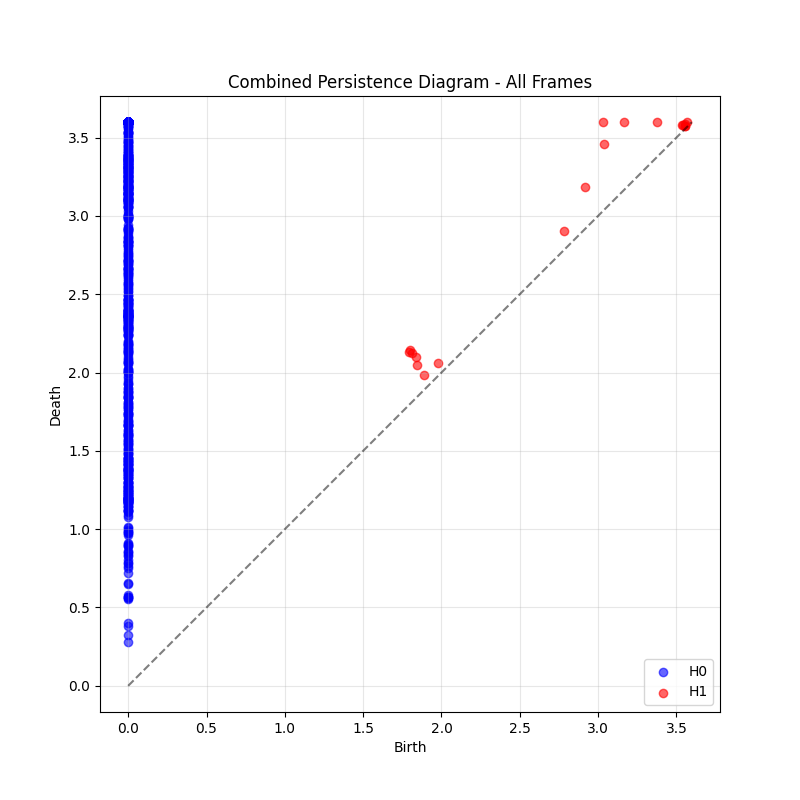

In [18]:
analysis = fullvranim.analyze_defensive_formation(gameId=2022091108, playId=751)

# Look at the results
print("Analysis Statistics:")
print(f"Average 0D persistence: {analysis['statistics']['avg_persistence_0D']:.2f}")
print(f"Average 1D persistence: {analysis['statistics']['avg_persistence_1D']:.2f}")
print(f"Maximum persistence: {analysis['statistics']['max_persistence']:.2f}")

# Show the persistence diagram
plt.show()